# Room-Temperature C-V Physical Modeling


In [1]:
# Import the C-V data, surface-potential PINN, and physical capacitance equations.
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from CV_DeviceData import load_cv_characteristics
from physics_loss import physics_loss
from CV_CgdSurfacePotential import DeltaPhiGdPINN, phi_gd_surface, save_cgd_pinn_pkl
from CVModeling import Cgd, Cds, Cgs, built_in_potential_4h_sic
from CVPhysicalModel import CVPhysicalParameters, save_cv_physical_pkl


## Data and constants

In [2]:
# Load the room-temperature low-voltage and 0-1000 V capacitance datasets.
device = torch.device("cpu")
dtype = torch.float32
torch.manual_seed(42)
BASE_DIR = Path.cwd()
TEMPLATE_DIR = BASE_DIR / "Template"
cv_data = load_cv_characteristics(TEMPLATE_DIR)
print(cv_data.groupby(["capacitance", "range"]).size())
print("Measured Vds range =", cv_data["Vds"].min(), "to", cv_data["Vds"].max(), "V")
assert np.allclose(cv_data["T_C"].to_numpy(), 25.0)


capacitance  range
Ciss         high     26
             low      17
Coss         high     28
             low      19
Crss         high     39
             low      28
dtype: int64
Measured Vds range = 0.0 to 589.3992933 V


In [3]:
# Use the same C-V voltage convention as the original physical equations and measured dataset.
T = 298.15
NA = 1.0e16
Eg = 3.26
eps_sic = 9.26 * 8.854e-14
Cox = 7.0e-8
Qox = 1.602e-7
Vfbs0 = -1.0
Dit_mid = 2.0e11
Dit_edge = 2.0e13
sigma_it = 0.1
Ec_minus_Ei = Eg / 2.0

VDG_MIN = 0.0
VDG_MAX = 1000.0
VDS_MIN = 0.0
VDS_MAX = 1000.0
CGD_PRETRAINED_PKL = BASE_DIR / "Cgd_PINN_pretrained.pkl"
CGD_PKL = BASE_DIR / "Cgd_PINN.pkl"
CV_PKL = BASE_DIR / "CV_physical_25C.pkl"
CV_BUNDLE_PKL = BASE_DIR / "CV_Model_25C.pkl"


## Pretrain the room-temperature Cgd surface-potential PINN


In [4]:
# Pretrain the surface-potential PINN on the C-V operating line before inverse fitting.
torch.manual_seed(42)
Model_Cgd = DeltaPhiGdPINN(VDG_MIN, VDG_MAX, VDS_MIN, VDS_MAX).to(device=device, dtype=dtype)
N_TRAIN = 2000
EPOCHS_GD = 2000
LEARNING_RATE_GD = 1.0e-3
Vds_train = torch.linspace(VDS_MIN, VDS_MAX, N_TRAIN, dtype=dtype, device=device).reshape(-1, 1)
Vgd_train = Vds_train.clone()
optimizer_gd = torch.optim.Adam(Model_Cgd.parameters(), lr=LEARNING_RATE_GD)
best_loss_gd = float("inf")
best_state_gd = None
gd_loss_history = []
for epoch in range(EPOCHS_GD):
    Model_Cgd.train()
    optimizer_gd.zero_grad(set_to_none=True)
    phigd = phi_gd_surface(Model_Cgd, Vgd_train, Vds_train, T=T, NA=NA, eps_sic=eps_sic, Cox=Cox, Vfbs0=Vfbs0, Dit_mid=Dit_mid, Dit_edge=Dit_edge, sigma_it=sigma_it, Eg=Eg, Qox=Qox)
    loss_gd = physics_loss(phigd, Vgd_train, Vds_train, T, NA, eps_sic, Cox, Vfbs0, Qox, Dit_mid, Dit_edge, sigma_it, Ec_minus_Ei, Eg)
    if not torch.isfinite(loss_gd):
        raise RuntimeError(f"Non-finite Cgd PINN physics loss at epoch {epoch}")
    loss_gd.backward()
    torch.nn.utils.clip_grad_norm_(Model_Cgd.parameters(), max_norm=1.0)
    optimizer_gd.step()
    value = loss_gd.item()
    gd_loss_history.append(value)
    if value < best_loss_gd:
        best_loss_gd = value
        best_state_gd = {key: value.detach().cpu().clone() for key, value in Model_Cgd.state_dict().items()}
    if epoch % 200 == 0 or epoch == EPOCHS_GD - 1:
        print(f"Cgd PINN epoch {epoch:4d} | L_SPE = {value:.6e}")
Model_Cgd.load_state_dict(best_state_gd, strict=True)
Model_Cgd.eval()
save_cgd_pinn_pkl(CGD_PRETRAINED_PKL, Model_Cgd, physical_parameters={"T_K": T, "NA": NA, "Cox": Cox, "Qox": Qox, "Vfbs0": Vfbs0, "Dit_mid": Dit_mid, "Dit_edge": Dit_edge, "sigma_it": sigma_it, "Eg": Eg}, training_metadata={"temperature_C": 25.0, "best_PI_loss": best_loss_gd, "epochs": EPOCHS_GD})


Cgd PINN epoch    0 | L_SPE = 3.965995e-04
Cgd PINN epoch  200 | L_SPE = 3.184268e-07
Cgd PINN epoch  400 | L_SPE = 1.140573e-07
Cgd PINN epoch  600 | L_SPE = 9.811122e-08
Cgd PINN epoch  800 | L_SPE = 9.466663e-08
Cgd PINN epoch 1000 | L_SPE = 9.146332e-08
Cgd PINN epoch 1200 | L_SPE = 8.864671e-08
Cgd PINN epoch 1400 | L_SPE = 8.593032e-08
Cgd PINN epoch 1600 | L_SPE = 8.789655e-08
Cgd PINN epoch 1800 | L_SPE = 8.170945e-08
Cgd PINN epoch 1999 | L_SPE = 8.036363e-08


## Fit the room-temperature physical C-V parameters with automatic differentiation


In [5]:
# Convert measured C-V points to tensors and preserve capacitance and voltage-range labels.
Vds_data = torch.tensor(cv_data["Vds"].to_numpy(np.float32), dtype=dtype, device=device).reshape(-1, 1)
C_measured_pF = torch.tensor(cv_data["Capacitance_pF"].to_numpy(np.float32), dtype=dtype, device=device).reshape(-1, 1)
cap_codes = {"Ciss": 0, "Coss": 1, "Crss": 2}
range_codes = {"low": 0, "high": 1}
cap_type = torch.tensor([cap_codes[name] for name in cv_data["capacitance"]], dtype=torch.long, device=device).reshape(-1, 1)
range_type = torch.tensor([range_codes[name] for name in cv_data["range"]], dtype=torch.long, device=device).reshape(-1, 1)

# Initialize the identifiable C-V parameters near physically supported values.
cv_parameters = CVPhysicalParameters(ND=4.289629e16, Agd_init=2.62e-3, Ads_init=3.60e-2, Coxgd_init=5.60e-7, Cgs_init=1177e-12, Vpt_init=520.0, Cjfet_min_init=7.39e-12).to(device=device, dtype=dtype)
print("Initial physical parameters =", cv_parameters.report(Cox))
print(cv_data.groupby(["capacitance", "range"]).size())


Initial physical parameters = {'ND': 4.289628651651072e+16, 'Agd': 0.0026199996937066317, 'Ads': 0.035999998450279236, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1770000529764957e-09, 'Vpt': 520.0001220703125, 'Cjfet_min': 7.389997468132403e-12}
capacitance  range
Ciss         high     26
             low      17
Coss         high     28
             low      19
Crss         high     39
             low      28
dtype: int64


In [6]:
def evaluate_cv(Vds):
    values = cv_parameters.values(Cox)
    Vds_cgd = torch.clamp(Vds, min=0.0)
    Vgd_cgd = Vds_cgd
    phigd = phi_gd_surface(Model_Cgd, Vgd_cgd, Vds_cgd, T=T, NA=NA, eps_sic=eps_sic, Cox=Cox, Vfbs0=Vfbs0, Dit_mid=Dit_mid, Dit_edge=Dit_edge, sigma_it=sigma_it, Eg=Eg, Qox=Qox)
    Vbi = built_in_potential_4h_sic(T, NA, values["ND"], Eg, Vds)
    Cgd_value = Cgd(phigd, Vds_cgd, T, NA, values["ND"], Eg, eps_sic, values["Agd"], values["Coxgd"], values["Cjfet_min"])
    Cds_value = Cds(Vds, values["ND"], eps_sic, values["Ads"], Vbi, values["Vpt"])
    Cgs_value = Cgs(Vds, values["Cgs_const"])
    return Cgs_value + Cgd_value, Cds_value + Cgd_value, Cgd_value, phigd, Vgd_cgd

def predicted_capacitance_pF(Vds, cap_type):
    Ciss, Coss, Crss, _, _ = evaluate_cv(Vds)
    predicted = torch.where(cap_type == 0, Ciss, torch.where(cap_type == 1, Coss, Crss))
    return predicted * 1.0e12

def all_predictions_pF():
    return predicted_capacitance_pF(Vds_data, cap_type)

def masked_log_loss(predicted_pF, mask):
    predicted_safe = torch.clamp(predicted_pF[mask], min=1.0e-6)
    measured_safe = torch.clamp(C_measured_pF[mask], min=1.0e-6)
    return torch.mean((torch.log10(predicted_safe) - torch.log10(measured_safe))**2)

def group_mask(cap_code, range_code):
    return ((cap_type[:, 0] == cap_code) & (range_type[:, 0] == range_code))

def balanced_cap_loss(predicted_pF, cap_code):
    return 0.5 * (masked_log_loss(predicted_pF, group_mask(cap_code, 0)) + masked_log_loss(predicted_pF, group_mask(cap_code, 1)))

def balanced_all_data_loss(predicted_pF):
    losses = [masked_log_loss(predicted_pF, group_mask(cap_code, range_code)) for cap_code in range(3) for range_code in range(2)]
    return sum(losses) / len(losses), losses


## Stage 2A: Fit Cgd-related physical parameters from Crss with the PINN frozen


In [7]:
# Fit only Agd and the high-voltage Cgd floor while keeping ND and Coxgd fixed.
for parameter in Model_Cgd.parameters():
    parameter.requires_grad_(False)

for parameter in cv_parameters.parameters():
    parameter.requires_grad_(False)

cv_parameters.log_Agd.requires_grad_(True)
cv_parameters.log_Cjfet_min.requires_grad_(True)

EPOCHS_CGD_PHYSICAL = 2000

optimizer_cgd_physical = torch.optim.Adam([cv_parameters.log_Agd, cv_parameters.log_Cjfet_min], lr=2.0e-3)
best_cgd_physical_loss = float("inf")
best_cgd_physical_state = None
cgd_physical_history = []
for epoch in range(EPOCHS_CGD_PHYSICAL):
    optimizer_cgd_physical.zero_grad(set_to_none=True)
    predicted_pF = all_predictions_pF()
    loss = balanced_cap_loss(predicted_pF, cap_codes["Crss"])
    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite Crss physical loss at epoch {epoch}")
    loss.backward()
    torch.nn.utils.clip_grad_norm_([parameter for parameter in cv_parameters.parameters() if parameter.requires_grad], max_norm=1.0)
    optimizer_cgd_physical.step()
    value = loss.item()
    cgd_physical_history.append(value)
    if value < best_cgd_physical_loss:
        best_cgd_physical_loss = value
        best_cgd_physical_state = {key: value.detach().cpu().clone() for key, value in cv_parameters.state_dict().items()}
    if epoch % 250 == 0 or epoch == EPOCHS_CGD_PHYSICAL - 1:
        print(f"Crss physical epoch {epoch:4d} | L_Crss = {value:.6e}")
cv_parameters.load_state_dict(best_cgd_physical_state, strict=True)
print("After Crss physical fit =", cv_parameters.report(Cox))


Crss physical epoch    0 | L_Crss = 2.227108e-01
Crss physical epoch  250 | L_Crss = 1.946470e-01
Crss physical epoch  500 | L_Crss = 1.940101e-01
Crss physical epoch  750 | L_Crss = 1.940095e-01
Crss physical epoch 1000 | L_Crss = 1.940095e-01
Crss physical epoch 1250 | L_Crss = 1.940095e-01
Crss physical epoch 1500 | L_Crss = 1.940095e-01
Crss physical epoch 1750 | L_Crss = 1.940095e-01
Crss physical epoch 1999 | L_Crss = 1.940095e-01
After Crss physical fit = {'ND': 4.289628651651072e+16, 'Agd': 0.0017776894383132458, 'Ads': 0.035999998450279236, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1770000529764957e-09, 'Vpt': 520.0001220703125, 'Cjfet_min': 4.741638505445511e-12}


## Stage 2B: Fine-tune the Cgd PINN and Cgd-related parameters against Crss


In [8]:
# Fine-tune the Cgd PINN together with only the identifiable Cgd parameters.
for parameter in Model_Cgd.parameters():
    parameter.requires_grad_(True)

for parameter in cv_parameters.parameters():
    parameter.requires_grad_(False)

cv_parameters.log_Agd.requires_grad_(True)
cv_parameters.log_Cjfet_min.requires_grad_(True)

EPOCHS_CGD_JOINT = 2000
CGD_PHYSICS_WEIGHT = 2.0e-3

optimizer_cgd_joint = torch.optim.Adam([
    {"params": Model_Cgd.parameters(), "lr": 4.0e-4},
    {"params": [cv_parameters.log_Agd, cv_parameters.log_Cjfet_min], "lr": 5.0e-4}
])
best_cgd_joint_loss = float("inf")
best_cgd_model_state = None
best_cgd_parameter_state = None
cgd_joint_history = []
cgd_joint_physics_history = []
for epoch in range(EPOCHS_CGD_JOINT):
    optimizer_cgd_joint.zero_grad(set_to_none=True)
    predicted_pF = all_predictions_pF()
    loss_data = balanced_cap_loss(predicted_pF, cap_codes["Crss"])
    idx = torch.randint(0, N_TRAIN, (min(512, N_TRAIN),), device=device)
    Vgd_physics = Vgd_train[idx]
    Vds_physics = Vds_train[idx]
    phigd_physics = phi_gd_surface(Model_Cgd, Vgd_physics, Vds_physics, T=T, NA=NA, eps_sic=eps_sic, Cox=Cox, Vfbs0=Vfbs0, Dit_mid=Dit_mid, Dit_edge=Dit_edge, sigma_it=sigma_it, Eg=Eg, Qox=Qox)
    loss_physics = physics_loss(phigd_physics, Vgd_physics, Vds_physics, T, NA, eps_sic, Cox, Vfbs0, Qox, Dit_mid, Dit_edge, sigma_it, Ec_minus_Ei, Eg)
    loss = loss_data + CGD_PHYSICS_WEIGHT * loss_physics
    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite Crss joint loss at epoch {epoch}")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(list(Model_Cgd.parameters()) + [parameter for parameter in cv_parameters.parameters() if parameter.requires_grad], max_norm=1.0)
    optimizer_cgd_joint.step()
    cgd_joint_history.append(loss_data.item())
    cgd_joint_physics_history.append(loss_physics.item())
    if loss.item() < best_cgd_joint_loss:
        best_cgd_joint_loss = loss.item()
        best_cgd_model_state = {key: value.detach().cpu().clone() for key, value in Model_Cgd.state_dict().items()}
        best_cgd_parameter_state = {key: value.detach().cpu().clone() for key, value in cv_parameters.state_dict().items()}
    if epoch % 250 == 0 or epoch == EPOCHS_CGD_JOINT - 1:
        print(f"Crss joint epoch {epoch:4d} | L_data = {loss_data.item():.6e} | L_SPE = {loss_physics.item():.6e}")
Model_Cgd.load_state_dict(best_cgd_model_state, strict=True)
cv_parameters.load_state_dict(best_cgd_parameter_state, strict=True)
print("After Crss joint fit =", cv_parameters.report(Cox))


Crss joint epoch    0 | L_data = 1.940095e-01 | L_SPE = 6.730108e-08
Crss joint epoch  250 | L_data = 1.356678e-01 | L_SPE = 2.236279e+00
Crss joint epoch  500 | L_data = 1.355913e-01 | L_SPE = 1.656126e+00
Crss joint epoch  750 | L_data = 1.355928e-01 | L_SPE = 1.445538e+00
Crss joint epoch 1000 | L_data = 1.355935e-01 | L_SPE = 1.377082e+00
Crss joint epoch 1250 | L_data = 1.356027e-01 | L_SPE = 8.158002e-01
Crss joint epoch 1500 | L_data = 1.356121e-01 | L_SPE = 7.070397e-01
Crss joint epoch 1750 | L_data = 1.356210e-01 | L_SPE = 5.297639e-01
Crss joint epoch 1999 | L_data = 1.356110e-01 | L_SPE = 5.251560e-01
After Crss joint fit = {'ND': 4.289628651651072e+16, 'Agd': 0.0015359902754426003, 'Ads': 0.035999998450279236, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1770000529764957e-09, 'Vpt': 520.0001220703125, 'Cjfet_min': 4.0914246816903255e-12}


## Stage 2C: Fit Cgs from Ciss


In [9]:
# Fit the nearly constant Cgs after fixing the fitted Cgd branch.
for parameter in Model_Cgd.parameters():
    parameter.requires_grad_(False)
for parameter in cv_parameters.parameters():
    parameter.requires_grad_(False)
cv_parameters.log_Cgs.requires_grad_(True)
EPOCHS_CGS = 1200
optimizer_cgs = torch.optim.Adam([cv_parameters.log_Cgs], lr=5.0e-3)
for epoch in range(EPOCHS_CGS):
    optimizer_cgs.zero_grad(set_to_none=True)
    predicted_pF = all_predictions_pF()
    loss = balanced_cap_loss(predicted_pF, cap_codes["Ciss"])
    loss.backward()
    optimizer_cgs.step()
    if epoch % 200 == 0 or epoch == EPOCHS_CGS - 1:
        print(f"Cgs epoch {epoch:4d} | L_Ciss = {loss.item():.6e}")
print("After Ciss fit =", cv_parameters.report(Cox))


Cgs epoch    0 | L_Ciss = 2.833418e-04
Cgs epoch  200 | L_Ciss = 2.422547e-04
Cgs epoch  400 | L_Ciss = 2.422547e-04
Cgs epoch  600 | L_Ciss = 2.422547e-04
Cgs epoch  800 | L_Ciss = 2.422547e-04
Cgs epoch 1000 | L_Ciss = 2.422547e-04
Cgs epoch 1199 | L_Ciss = 2.422546e-04
After Ciss fit = {'ND': 4.289628651651072e+16, 'Agd': 0.0015359902754426003, 'Ads': 0.035999998450279236, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1592452553443877e-09, 'Vpt': 520.0001220703125, 'Cjfet_min': 4.0914246816903255e-12}


## Stage 2D: Fit Cds parameters from Coss


In [10]:
# Fit the Cds branch after fixing the Cgd and Cgs branches.
for parameter in cv_parameters.parameters():
    parameter.requires_grad_(False)
cv_parameters.log_Ads.requires_grad_(True)
cv_parameters.log_Vpt.requires_grad_(True)
EPOCHS_CDS = 2000
optimizer_cds = torch.optim.Adam([cv_parameters.log_Ads, cv_parameters.log_Vpt], lr=2.0e-3)
for epoch in range(EPOCHS_CDS):
    optimizer_cds.zero_grad(set_to_none=True)
    predicted_pF = all_predictions_pF()
    loss = balanced_cap_loss(predicted_pF, cap_codes["Coss"])
    loss.backward()
    torch.nn.utils.clip_grad_norm_([cv_parameters.log_Ads, cv_parameters.log_Vpt], max_norm=1.0)
    optimizer_cds.step()
    if epoch % 250 == 0 or epoch == EPOCHS_CDS - 1:
        print(f"Cds epoch {epoch:4d} | L_Coss = {loss.item():.6e}")
print("After Coss fit =", cv_parameters.report(Cox))


Cds epoch    0 | L_Coss = 1.002137e-02
Cds epoch  250 | L_Coss = 7.191554e-03
Cds epoch  500 | L_Coss = 7.191560e-03
Cds epoch  750 | L_Coss = 7.191560e-03
Cds epoch 1000 | L_Coss = 7.191560e-03
Cds epoch 1250 | L_Coss = 7.191560e-03
Cds epoch 1500 | L_Coss = 7.191560e-03
Cds epoch 1750 | L_Coss = 7.191560e-03
Cds epoch 1999 | L_Coss = 7.191560e-03
After Coss fit = {'ND': 4.289628651651072e+16, 'Agd': 0.0015359902754426003, 'Ads': 0.03145167976617813, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1592452553443877e-09, 'Vpt': 390.8348388671875, 'Cjfet_min': 4.0914246816903255e-12}


## Stage 2E: Final balanced inverse fine-tuning


In [11]:
# Fine-tune only identifiable physical parameters while keeping ND and Coxgd fixed.
for parameter in Model_Cgd.parameters():
    parameter.requires_grad_(True)

for parameter in cv_parameters.parameters():
    parameter.requires_grad_(False)

cv_parameters.log_Agd.requires_grad_(True)
cv_parameters.log_Ads.requires_grad_(True)
cv_parameters.log_Cgs.requires_grad_(True)
cv_parameters.log_Vpt.requires_grad_(True)
cv_parameters.log_Cjfet_min.requires_grad_(True)
trainable_cv_parameters = [
    cv_parameters.log_Agd,
    cv_parameters.log_Ads,
    cv_parameters.log_Cgs,
    cv_parameters.log_Vpt,
    cv_parameters.log_Cjfet_min
]

EPOCHS_FINAL = 500
FINAL_PHYSICS_WEIGHT = 1.0e-3

optimizer_final = torch.optim.Adam([
    {"params": Model_Cgd.parameters(), "lr": 5.0e-5},
    {"params": trainable_cv_parameters, "lr": 1.0e-4}
])
best_final_loss = float("inf")
best_final_model_state = None
best_final_parameter_state = None
final_data_history = []
final_physics_history = []
for epoch in range(EPOCHS_FINAL):
    optimizer_final.zero_grad(set_to_none=True)
    predicted_pF = all_predictions_pF()
    loss_data, group_losses = balanced_all_data_loss(predicted_pF)
    idx = torch.randint(0, N_TRAIN, (min(512, N_TRAIN),), device=device)
    Vgd_physics = Vgd_train[idx]
    Vds_physics = Vds_train[idx]
    phigd_physics = phi_gd_surface(Model_Cgd, Vgd_physics, Vds_physics, T=T, NA=NA, eps_sic=eps_sic, Cox=Cox, Vfbs0=Vfbs0, Dit_mid=Dit_mid, Dit_edge=Dit_edge, sigma_it=sigma_it, Eg=Eg, Qox=Qox)
    loss_physics = physics_loss(phigd_physics, Vgd_physics, Vds_physics, T, NA, eps_sic, Cox, Vfbs0, Qox, Dit_mid, Dit_edge, sigma_it, Ec_minus_Ei, Eg)
    loss = loss_data + FINAL_PHYSICS_WEIGHT * loss_physics
    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite final inverse loss at epoch {epoch}")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(list(Model_Cgd.parameters()) + trainable_cv_parameters, max_norm=1.0)
    optimizer_final.step()
    final_data_history.append(loss_data.item())
    final_physics_history.append(loss_physics.item())
    if loss.item() < best_final_loss:
        best_final_loss = loss.item()
        best_final_model_state = {key: value.detach().cpu().clone() for key, value in Model_Cgd.state_dict().items()}
        best_final_parameter_state = {key: value.detach().cpu().clone() for key, value in cv_parameters.state_dict().items()}
    if epoch % 250 == 0 or epoch == EPOCHS_FINAL - 1:
        print(f"Final epoch {epoch:4d} | L_data = {loss_data.item():.6e} | L_SPE = {loss_physics.item():.6e}")
Model_Cgd.load_state_dict(best_final_model_state, strict=True)
cv_parameters.load_state_dict(best_final_parameter_state, strict=True)
Model_Cgd.eval()
cv_parameters.eval()
print("Final physical parameters =", cv_parameters.report(Cox))


Final epoch    0 | L_data = 4.768262e-02 | L_SPE = 5.035003e-01
Final epoch  250 | L_data = 4.768736e-02 | L_SPE = 3.474759e-01
Final epoch  499 | L_data = 4.769206e-02 | L_SPE = 4.989544e-01
Final physical parameters = {'ND': 4.289628651651072e+16, 'Agd': 0.0015417850809171796, 'Ads': 0.03144450485706329, 'Coxgd': 5.599997621175135e-07, 'Cgs_const': 1.1591015924850012e-09, 'Vpt': 390.8111877441406, 'Cjfet_min': 4.0914246816903255e-12}


## Room-temperature C-V comparison


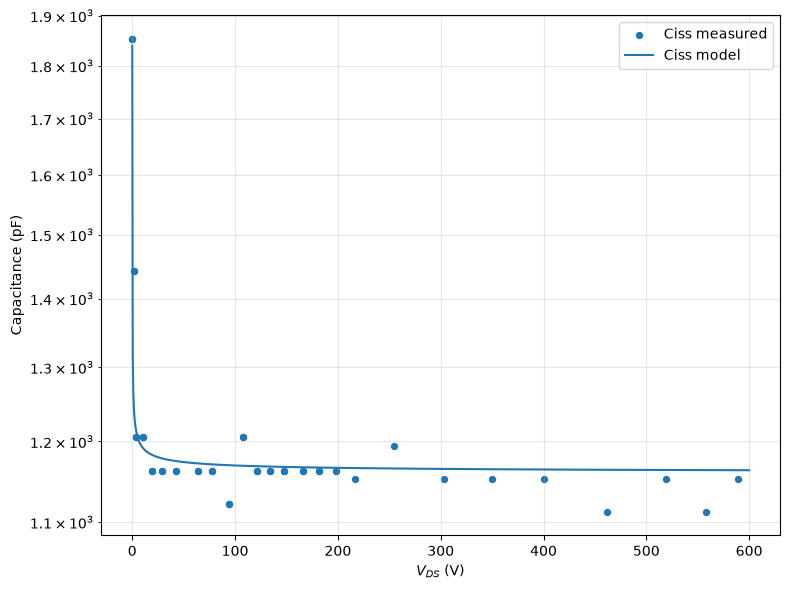

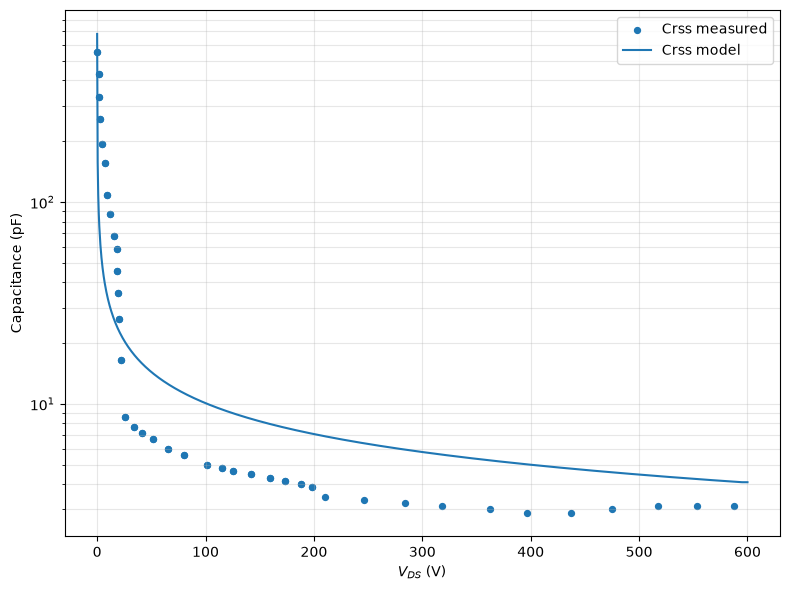

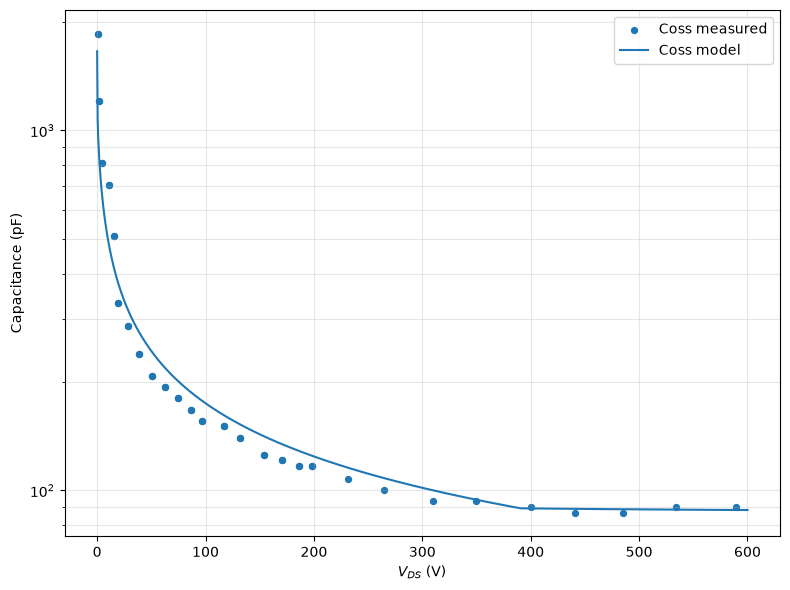

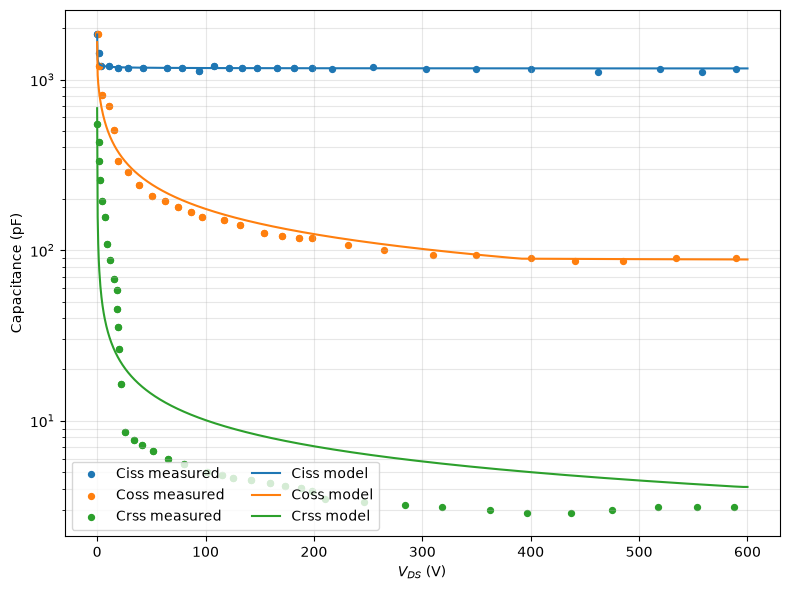

In [12]:
# Compare the fitted room-temperature Ciss, Crss, and Coss curves with both measured voltage ranges.
Vds_plot = torch.linspace(0.0, 600.0, 1200, dtype=dtype, device=device).reshape(-1, 1)

#If curves are needed to be plotted only for the measured voltage range, summon codes below
#VDS_PLOT_MAX = float(cv_data["Vds"].max())
#Vds_plot = torch.linspace(0.0, VDS_PLOT_MAX, 1200, dtype=dtype, device=device).reshape(-1, 1)


Model_Cgd.eval()
cv_parameters.eval()

with torch.no_grad():
    Ciss_plot, Coss_plot, Crss_plot, _, _ = evaluate_cv(Vds_plot)

# Plot Ciss separately.
part = cv_data[cv_data["capacitance"] == "Ciss"]

plt.figure(figsize=(8, 6))
plt.scatter(part["Vds"], part["Capacitance_pF"], s=18, label="Ciss measured")
plt.plot(Vds_plot.cpu(), (Ciss_plot * 1.0e12).cpu(), label="Ciss model")
plt.xlabel(r"$V_{DS}$ (V)")
plt.ylabel("Capacitance (pF)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot Crss separately.
part = cv_data[cv_data["capacitance"] == "Crss"]

plt.figure(figsize=(8, 6))
plt.scatter(part["Vds"], part["Capacitance_pF"], s=18, label="Crss measured")
plt.plot(Vds_plot.cpu(), (Crss_plot * 1.0e12).cpu(), label="Crss model")
plt.xlabel(r"$V_{DS}$ (V)")
plt.ylabel("Capacitance (pF)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot Coss separately.
part = cv_data[cv_data["capacitance"] == "Coss"]

plt.figure(figsize=(8, 6))
plt.scatter(part["Vds"], part["Capacitance_pF"], s=18, label="Coss measured")
plt.plot(Vds_plot.cpu(), (Coss_plot * 1.0e12).cpu(), label="Coss model")
plt.xlabel(r"$V_{DS}$ (V)")
plt.ylabel("Capacitance (pF)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot Ciss, Coss, and Crss together.
plt.figure(figsize=(8, 6))

for name in ["Ciss", "Coss", "Crss"]:
    part = cv_data[cv_data["capacitance"] == name]
    plt.scatter(part["Vds"], part["Capacitance_pF"], s=18, label=f"{name} measured")

for values, name in [(Ciss_plot, "Ciss model"), (Coss_plot, "Coss model"), (Crss_plot, "Crss model")]:
    plt.plot(Vds_plot.cpu(), (values * 1.0e12).cpu(), label=name)

plt.xlabel(r"$V_{DS}$ (V)")
plt.ylabel("Capacitance (pF)")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

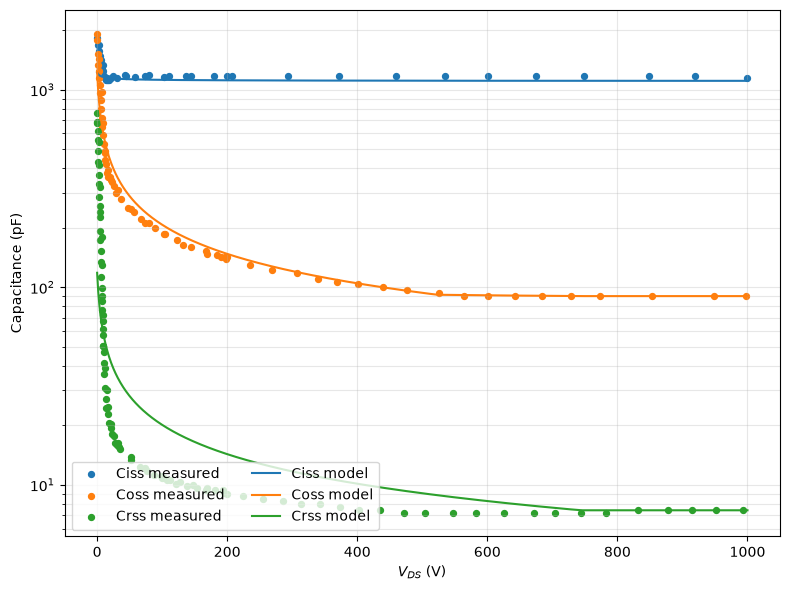

## Save the final Cgd PINN and physical C-V parameters as .pkl


In [13]:
# Save the final surface-potential PINN and fitted C-V physical parameters.
save_cgd_pinn_pkl(CGD_PKL, Model_Cgd, physical_parameters={"T_K": T, "NA": NA, "Cox": Cox, "Qox": Qox, "Vfbs0": Vfbs0, "Dit_mid": Dit_mid, "Dit_edge": Dit_edge, "sigma_it": sigma_it, "Eg": Eg}, training_metadata={"temperature_C": 25.0, "best_pretrain_PI_loss": best_loss_gd, "best_Crss_joint_loss": best_cgd_joint_loss, "best_final_loss": best_final_loss})
save_cv_physical_pkl(CV_PKL, cv_parameters, training_metadata={"temperature_C": 25.0, "best_Crss_physical_loss": best_cgd_physical_loss, "best_Crss_joint_loss": best_cgd_joint_loss, "best_final_loss": best_final_loss})
cv_bundle = {"format_version": 4, "model_name": "SiC_MOSFET_CV_25C_", "temperature_C": 25.0, "training_scheme": "physics_pretrain_then_hierarchical_inverse_fit_then_balanced_joint_finetune", "Cgd_surface_PINN": torch.load(CGD_PKL, map_location="cpu", weights_only=False), "CV_physical": torch.load(CV_PKL, map_location="cpu", weights_only=False)}
torch.save(cv_bundle, CV_BUNDLE_PKL)
print("Saved Cgd_PINN.pkl, CV_physical_25C.pkl, and CV_Model_25C.pkl")


Saved Cgd_PINN.pkl, CV_physical_25C.pkl, and CV_Model_25C.pkl
